# 06 - Machine learning: what each modality can and cannot support

Three modelling questions, each chosen because its answer informs a decision rather than to maximise a score:

1. **Speed classification by modality.** Which sensors carry walking-state information that generalises
   to people the model has never seen? This is the realistic deployment setting, so every model is
   validated with participants held out as whole groups. The same models are also scored with a naive split
   to show how much a careless protocol would overstate performance.
2. **Is EEG decoding brain activity?** Notebook 05 showed the walking EEG is dominated by gait-locked
   artefact. Here the EEG model is compared with a model that sees only the artefact indices.
3. **Re-identification.** Can a person be recognised from their walking data recorded at a different
   speed? A yes means the data are biometric and must be governed as personal data, regardless of whether
   names are removed.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from mgait import config as C, features as F, models as Mo, plotting as P, stats as S

P.use_style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
T = pd.read_parquet(C.TABLES / "trial_features.parquet")
T = T[~((T.subject == "S8") & (T.speed == "0.5"))]  # EEG timing gap; keeps the comparison on one trial set
mc = F.modality_columns(T)
eeg_art = [c for c in mc["EEG"] if c.endswith(("harmonic_ratio", "head_coherence"))]
eeg_spec = [c for c in mc["EEG"] if c not in eeg_art]
sets = {"Force plates": mc["Force plates"], "IMU": mc["IMU"], "EMG": mc["EMG"],
        "EEG (band power)": eeg_spec, "EEG artefact indices only": eeg_art,
        "Force plates + IMU + EMG": mc["Force plates"] + mc["IMU"] + mc["EMG"]}
complete = T[[c for k in ("Force plates", "IMU", "EMG") for c in mc[k]] + eeg_spec].notna().mean(axis=1) > 0.8
D = T[complete & T["all4"]].reset_index(drop=True)
y, g = D["speed"].to_numpy(), D["subject"].to_numpy()
print(f"Common trial set: {len(D)} trials, {D.subject.nunique()} participants; "
      f"class balance {pd.Series(y).value_counts().to_dict()}")

Common trial set: 160 trials, 57 participants; class balance {'0.5': 56, '0.75': 54, '1': 50}


## 1. Walking-speed classification

Three classes (0.50, 0.75, 1.00 m/s), chance = 33 %. Logistic regression and random forest, 10-fold
cross-validation grouped by participant; the 95 % interval resamples participants.

In [2]:
rows, preds = [], {}
for name, cols in sets.items():
    X = D[cols].to_numpy(float)
    for mname, model in Mo.classifiers().items():
        yhat = Mo.cv_predict(model, X, y, g)
        sc = Mo.score_classification(y, yhat, g)
        yhat_naive = Mo.cv_predict(model, X, y, None)
        rows.append({"features": name, "model": mname, "n_features": len(cols),
                     "balanced accuracy (subject-wise)": sc["balanced_accuracy"],
                     "95% CI": f"{sc['acc_ci_lo']:.2f} to {sc['acc_ci_hi']:.2f}",
                     "balanced accuracy (record-wise)": Mo.balanced_accuracy_score(y, yhat_naive)})
        preds[(name, mname)] = yhat
spd = pd.DataFrame(rows)
spd.to_csv(C.TABLES / "ml_speed_classification.csv", index=False)
display(spd.set_index(["features", "model"]).round(3))

n_features  balanced accuracy (subject-wise)        95% CI  balanced accuracy (record-wise)
features                  model                                                                                                           
Force plates              Logistic regression          18                             0.975  0.94 to 1.00                            0.975
                          Random forest                18                             0.987  0.97 to 1.00                            0.993
IMU                       Logistic regression          15                             0.885  0.84 to 0.93                            0.893
                          Random forest                15                             0.881  0.82 to 0.94                            0.874
EMG                       Logistic regression          18                             0.546  0.49 to 0.60                            0.502
                          Random forest                18                             0.670  0.60 to 0.75                            0.571
EEG (band power)          Logistic regression          30                             0.491  0.43 to 0.56                            0.424
                          Random forest                30                             0.468  0.41 to 0.52                            0.381
EEG artefact indices only Logistic regression          10                             0.621  0.55 to 0.69                            0.596
                          Random forest                10                             0.596  0.52 to 0.67                            0.590
Force plates + IMU + EMG  Logistic regression          51                             1.000  1.00 to 1.00                            1.000
                          Random forest                51                             0.974  0.94 to 1.00                            0.987

At trial level the naive (record-wise) split changes little, because each trial is one row and a
participant's other trials are at *different* speeds. The inflation appears when models are trained on
strides: strides of the same trial are near-duplicates, so a random split places a trial's own strides in
both training and test folds.

In [3]:
imu = pd.read_parquet(C.CACHE / "imu_strides.parquet")
ist = imu[imu["qc_ok"]].dropna(subset=F.IMU_FEATURES).reset_index(drop=True)
Xs, ys, gs = ist[F.IMU_FEATURES].to_numpy(), ist["speed"].to_numpy(), ist["subject"].to_numpy()
lr = Mo.classifiers()["Logistic regression"]
rf = Mo.classifiers()["Random forest"]
leak = []
for mname, model in (("Logistic regression", lr), ("Random forest", rf)):
    a_rec = Mo.balanced_accuracy_score(ys, Mo.cv_predict(model, Xs, ys, None, n_splits=5))
    a_sub = Mo.balanced_accuracy_score(ys, Mo.cv_predict(model, Xs, ys, gs, n_splits=5))
    leak.append({"model": mname, "strides": len(ys), "random stride split": a_rec, "participant-wise split": a_sub,
                 "overstatement (points)": 100 * (a_rec - a_sub)})
leak = pd.DataFrame(leak).set_index("model")
leak.to_csv(C.TABLES / "ml_leakage_demo.csv")
display(leak.round(3))

,strides,random stride split,participant-wise split,overstatement (points)
model,,,,
Logistic regression,14964,0.927,0.904,2.264
Random forest,14964,0.976,0.848,12.800


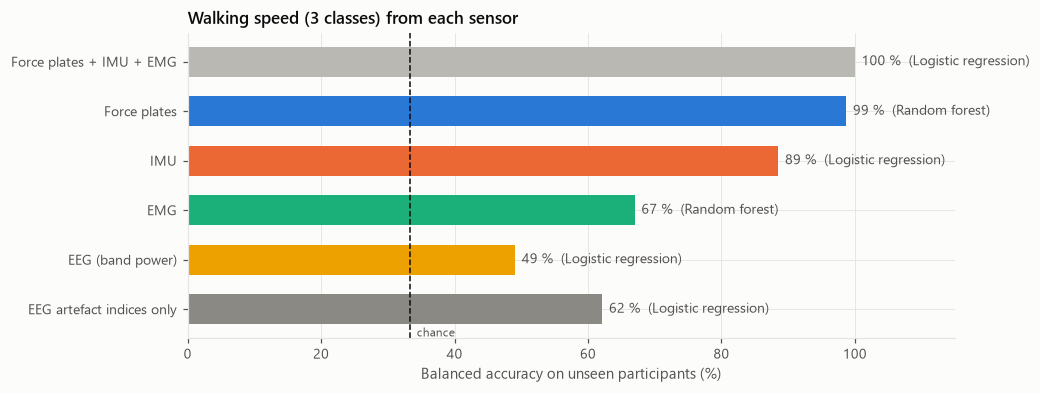

In [4]:
best = spd.loc[spd.groupby("features")["balanced accuracy (subject-wise)"].idxmax()].set_index("features")
order = ["Force plates + IMU + EMG", "Force plates", "IMU", "EMG", "EEG (band power)", "EEG artefact indices only"]
best = best.loc[order]
fig, ax = plt.subplots(figsize=(9, 3.6))
cols_ = [P.NEUTRAL, P.MODALITY_COLORS["Force plates"], P.MODALITY_COLORS["IMU"], P.MODALITY_COLORS["EMG"],
         P.MODALITY_COLORS["EEG"], P.MUTED]
yy = np.arange(len(order))[::-1]
ax.barh(yy, 100 * best["balanced accuracy (subject-wise)"], color=cols_, height=0.6)
for yi, (nm, r) in zip(yy, best.iterrows()):
    ax.text(100 * r["balanced accuracy (subject-wise)"] + 1, yi, f"{100 * r['balanced accuracy (subject-wise)']:.0f} %  ({r['model']})",
            va="center", fontsize=9, color=P.INK2)
ax.axvline(100 / 3, color=P.INK, ls="--", lw=1)
ax.text(100 / 3 + 1, yy[-1] - 0.55, "chance", fontsize=8, color=P.INK2)
ax.set_yticks(yy, order)
ax.set_xlim(0, 115)
ax.set_xlabel("Balanced accuracy on unseen participants (%)")
ax.set_title("Walking speed (3 classes) from each sensor")
P.save(fig, "06_speed_by_modality")
plt.show()

## 2. Is the EEG model reading the brain?

If the EEG band-power model's accuracy came from cortical activity, a model given only the two artefact
indices (step-locked spectral power and head-motion coherence per region) should do much worse. A
permutation test (labels shuffled within participant) gives the chance distribution for the EEG models.

In [5]:
for name in ("EEG (band power)", "EEG artefact indices only"):
    X = D[sets[name]].to_numpy(float)
    obs = np.mean(Mo.cv_predict(lr, X, y, g) == y)
    null = Mo.permutation_null(lr, X, y, g, n_perm=100)
    print(f"{name}: accuracy {obs:.3f}; permutation null {null.mean():.3f} (95th pct {np.percentile(null, 95):.3f}); "
          f"p = {(1 + (null >= obs).sum()) / (1 + len(null)):.3f}")
Xb = D[eeg_spec].to_numpy(float)
Xa = D[eeg_art].to_numpy(float)
pb = Mo.cv_predict(lr, Xb, y, g)
pa = Mo.cv_predict(lr, Xa, y, g)
agree = np.mean(pb == pa)
print(f"The two EEG models make the same prediction on {100 * agree:.0f} % of trials")

EEG (band power): accuracy 0.494; permutation null 0.334 (95th pct 0.394); p = 0.010


EEG artefact indices only: accuracy 0.625; permutation null 0.335 (95th pct 0.400); p = 0.010


The two EEG models make the same prediction on 54 % of trials


## 3. Re-identification across walking speeds

For each modality a participant classifier is trained on two speeds and tested on the third (each speed held
out in turn). Force plates, IMU and EMG use stride-level curves and stride parameters; test predictions are
averaged over the strides of a trial. EEG uses one vector of log band power per channel per trial and a
nearest-neighbour match. Chance is one over the number of participants.

Caveat: all three speeds were recorded in one session with the same sensor placement, so this measures
recognition across walking conditions, not across days. For EMG and EEG in particular, electrode placement
and impedance are part of what is recognised.

In [6]:
fp = pd.read_parquet(C.CACHE / "fp_strides.parquet"); fpc = dict(np.load(C.CACHE / "fp_curves.npz"))
ic = dict(np.load(C.CACHE / "imu_curves.npz"))
em = pd.read_parquet(C.CACHE / "emg_strides.parquet"); ecv = dict(np.load(C.CACHE / "emg_curves.npz"))

def stride_matrix(kind):
    if kind == "Force plates":
        ok = fp["qc_ok"].to_numpy()
        X = np.hstack([fpc[k][ok][:, ::4] for k in ("Fz", "Fy", "Fx")] +
                      [fp.loc[ok, ["stride_time", "stance_pct", "double_support_pct"]].to_numpy()])
        meta = fp.loc[ok, ["subject", "speed", "side"]]
    elif kind == "IMU":
        ok = imu["qc_ok"].to_numpy()
        X = np.hstack([ic[k][ok][:, ::4] for k in ("hip_flex", "knee_flex", "ankle_dorsi", "hip_abd")] +
                      [imu.loc[ok, ["stride_time", "stance_pct"]].to_numpy()])
        meta = imu.loc[ok, ["subject", "speed", "side"]]
    else:
        X = np.hstack([np.log10(np.clip(ecv[m][:, ::4], 1e-3, None)) for m in C.MUSCLES])
        ok = ~np.isnan(X).any(axis=1)
        X, meta = X[ok], em.loc[ok, ["subject", "speed", "side"]]
    X = np.hstack([X, (meta["side"] == "L").to_numpy()[:, None].astype(float)])
    return X, meta.reset_index(drop=True)

id_rows = []
for kind in ("Force plates", "IMU", "EMG"):
    X, meta = stride_matrix(kind)
    have = meta.groupby("subject")["speed"].nunique()
    subj = have[have == 3].index
    sel = meta["subject"].isin(subj).to_numpy()
    X, meta = X[sel], meta[sel].reset_index(drop=True)
    for test_speed in C.SPEEDS:
        tr, te = (meta["speed"] != test_speed).to_numpy(), (meta["speed"] == test_speed).to_numpy()
        model = make_pipeline(StandardScaler(), PCA(40, random_state=C.SEED), LogisticRegression(C=0.5, max_iter=3000))
        model.fit(X[tr], meta.loc[tr, "subject"])
        proba = model.predict_proba(X[te])
        cls = model.classes_
        stride_acc = np.mean(cls[proba.argmax(1)] == meta.loc[te, "subject"].to_numpy())
        tp = pd.DataFrame(np.log(proba + 1e-12), columns=cls)
        tp["subject"] = meta.loc[te, "subject"].to_numpy()
        trial_pred = tp.groupby("subject").mean().idxmax(axis=1)
        id_rows.append({"modality": kind, "test speed": test_speed, "participants": len(subj),
                        "stride accuracy": stride_acc, "trial accuracy": np.mean(trial_pred.index == trial_pred.values),
                        "chance": 1 / len(subj)})

# EEG: log band power per channel, nearest neighbour (correlation) across speeds
psd = np.load(C.CACHE / "eeg_psd.npz")
fq, Pw, keys = psd["f"], psd["P"], [k for k in psd["keys"]]
bands = [(1, 4), (4, 8), (8, 13), (13, 30), (30, 45)]
feat = np.stack([np.log10(np.stack([Pw[i][(fq >= lo) & (fq < hi)].mean(0) for lo, hi in bands]).ravel()) for i in range(len(keys))])
km = pd.DataFrame({"subject": [k.rsplit("_", 1)[0] for k in keys], "speed": [k.rsplit("_", 1)[1] for k in keys]})
keep = ~((km.subject == "S8") & (km.speed == "0.5"))
have = km[keep].groupby("subject")["speed"].nunique()
subj = have[have == 3].index
for test_speed in C.SPEEDS:
    te = (keep & km.subject.isin(subj) & (km.speed == test_speed)).to_numpy()
    tr = (keep & km.subject.isin(subj) & (km.speed != test_speed)).to_numpy()
    Z = (feat - feat[tr].mean(0)) / feat[tr].std(0)
    R = np.corrcoef(Z[te], Z[tr])[:te.sum(), te.sum():]
    pred = km.loc[tr, "subject"].to_numpy()[R.argmax(1)]
    id_rows.append({"modality": "EEG", "test speed": test_speed, "participants": len(subj), "stride accuracy": np.nan,
                    "trial accuracy": np.mean(pred == km.loc[te, "subject"].to_numpy()), "chance": 1 / len(subj)})
ident = pd.DataFrame(id_rows)
ident.to_csv(C.TABLES / "ml_reidentification.csv", index=False)
display(ident.set_index(["modality", "test speed"]).round(3))
id_sum = ident.groupby("modality")[["participants", "stride accuracy", "trial accuracy", "chance"]].mean()
display(id_sum.round(3))

participants  stride accuracy  trial accuracy  chance
modality     test speed                                                       
Force plates 0.5                   56            0.465           0.661   0.018
             0.75                  56            0.939           1.000   0.018
             1                     56            0.708           0.946   0.018
IMU          0.5                   55            0.641           0.836   0.018
             0.75                  55            0.980           1.000   0.018
             1                     55            0.882           0.964   0.018
EMG          0.5                   48            0.570           0.938   0.021
             0.75                  48            0.885           1.000   0.021
             1                     48            0.660           0.833   0.021
EEG          0.5                   57              NaN           0.789   0.018
             0.75                  57              NaN           0.912   0.018
             1                     57              NaN           0.912   0.018

,participants,stride accuracy,trial accuracy,chance
modality,,,,
EEG,57.0,NaN,0.871,0.018
EMG,48.0,0.705,0.924,0.021
Force plates,56.0,0.704,0.869,0.018
IMU,55.0,0.834,0.933,0.018


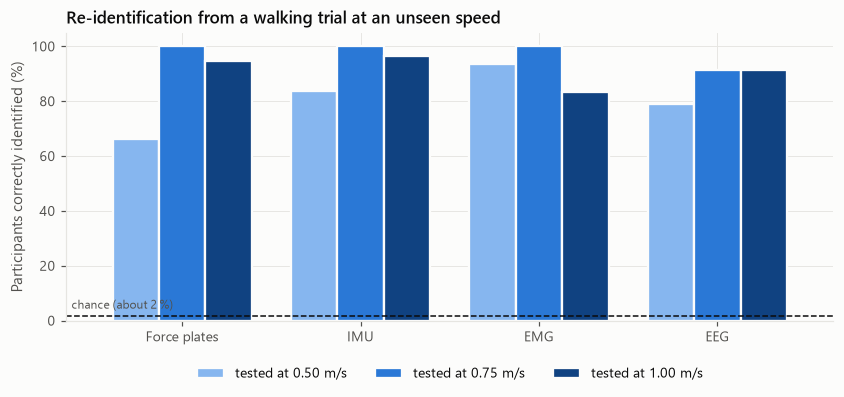

In [7]:
mods = ["Force plates", "IMU", "EMG", "EEG"]
fig, ax = plt.subplots(figsize=(9, 3.4))
xx = np.arange(len(mods))
for i, s in enumerate(C.SPEEDS):
    v = ident[ident["test speed"] == s].set_index("modality").loc[mods, "trial accuracy"]
    ax.bar(xx + (i - 1) * 0.26, 100 * v, width=0.26, color=P.SPEED_COLORS[s], label=f"tested at {P.SPEED_LABEL[s]}",
           edgecolor=P.SURFACE, linewidth=1.5)
ax.axhline(100 * id_sum["chance"].mean(), color=P.INK, ls="--", lw=1)
ax.text(-0.62, 100 * id_sum["chance"].mean() + 2.5, "chance (about 2 %)", fontsize=8, color=P.INK2, ha="left")
ax.set_xlim(-0.65, len(mods) - 0.35)
ax.set_xticks(xx, mods)
ax.set_ylabel("Participants correctly identified (%)")
ax.set_title("Re-identification from a walking trial at an unseen speed")
ax.set_ylim(0, 105)
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.12))
P.save(fig, "06_reidentification")
plt.show()

## 4. Sensitive attribute inference

Gait features also reveal attributes a participant did not disclose to the model. As an example, sex is
predicted from force-plate and IMU trial features (one prediction per participant, averaged over trials),
with participants held out.

In [8]:
cols = mc["Force plates"] + mc["IMU"]
Dx = T[T["fp"] & T["imu"]].dropna(subset=["sex"]).reset_index(drop=True)
ys_ = Dx["sex"].to_numpy(); gs_ = Dx["subject"].to_numpy()
pr = Mo.cv_predict(Mo.classifiers()["Logistic regression"], Dx[cols].to_numpy(float), ys_, gs_, proba=True)
pp = pd.DataFrame(pr, columns=sorted(np.unique(ys_))); pp["subject"], pp["sex"] = gs_, ys_
per = pp.groupby("subject").agg(F_=("F", "mean"), sex=("sex", "first"))
acc_sex = np.mean(np.where(per["F_"] > 0.5, "F", "M") == per["sex"])
base_sex = per["sex"].value_counts(normalize=True).max()
print(f"Sex predicted from gait (participant level): {100 * acc_sex:.0f} % correct vs {100 * base_sex:.0f} % majority-class baseline "
      f"(n = {len(per)}); features are expressed per body weight and leg length where applicable")

Sex predicted from gait (participant level): 88 % correct vs 62 % majority-class baseline (n = 58); features are expressed per body weight and leg length where applicable


## 5. Summary

| Question | Result (participants held out) | Implication |
|---|---|---|
| Speed from force plates | 98-99 % balanced accuracy | Reference-grade, but tied to the treadmill |
| Speed from IMU | 88-89 % (the suit's own speed estimate, excluded here, is within 4.3 %) | Portable sensing carries most of the information |
| Speed from EMG | 55-67 % | Adds muscle-level insight, weak on its own |
| Speed from EEG band power | 49 % (chance 33 %, permutation p = 0.01) | Above chance, but... |
| Speed from EEG artefact indices only | 62 % | ...two artefact indices beat 30 band-power features: the EEG signal is mechanics |
| Fused force plates + IMU + EMG | 97-100 % | Fusion adds little over force plates alone |
| Naive stride-level split | Overstates random-forest accuracy by 13 points (98 % vs 85 %) | Participant-wise validation is non-negotiable |
| Re-identification at an unseen speed | 87 % (EEG, force plates) to 93 % (IMU) of participants, chance 2 % | Every modality is a biometric identifier |
| Sex inferred from gait | 88 % vs 62 % baseline | Gait data disclose sensitive attributes |

The models confirm the earlier notebooks from a different angle. Walking state is carried by the
biomechanical signals, with the IMU close behind the force plates. The EEG adds no information that its
own artefact indices do not already carry. And every modality identifies people across walking
conditions, so the data require the governance of biometric personal data, not merely removal of names.